# What wins a Premier League season? Evidence from 2007-08

**Author:** Jeetrajsinh Jadeja · MSc Digital Finance & Data Analytics, Nottingham Trent University

## Questions
1. **Home advantage:** do home teams score significantly more than away teams?
2. **Shot quality vs volume:** what separates the top of the table from the bottom: taking more shots, or hitting the target more often?
3. **Can one metric explain final points?** How much of the variation in league points does *shots-on-target difference* explain?

## Data
`2007-08.csv` from [football-data.co.uk](https://www.football-data.co.uk/englandm.php): every match of the 2007-08 Premier League season (380 matches, 20 teams).

| Column | Meaning | Column | Meaning |
|---|---|---|---|
| FTHG / FTAG | Full-time home / away goals | HS / AS | Home / away shots |
| FTR | Full-time result (H/D/A) | HST / AST | Home / away shots on target |
| HTHG / HTAG | Half-time goals | HF / AF | Fouls |
| HC / AC | Corners | HY, AY, HR, AR | Yellow / red cards |

## How to reproduce
1. Open this notebook in Google Colab.
2. Upload `2007-08.csv` using the folder icon on the left, then **Upload**.
3. **Runtime → Run all.** Every number and chart below comes from the code in this notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load and check the data

In [2]:
df = pd.read_csv("2007-08.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%y")   # UK date format dd/mm/yy

print("Rows, columns:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Teams:", df["HomeTeam"].nunique())
print("Season runs", df["Date"].min().date(), "to", df["Date"].max().date())
df.head()

Rows, columns: (380, 23)
Missing values: 0
Teams: 20
Season runs 2007-08-11 to 2008-05-11


,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
0,E0,2007-08-11,Aston Villa,Liverpool,1,2,A,0,1,A,...,6,7,18,11,4,2,4,2,0,0
1,E0,2007-08-11,Bolton,Newcastle,1,3,A,0,3,A,...,9,5,15,16,4,3,1,1,0,0
2,E0,2007-08-11,Derby,Portsmouth,2,2,D,1,1,D,...,5,6,14,17,6,6,1,2,0,0
3,E0,2007-08-11,Everton,Wigan,2,1,H,1,0,H,...,8,4,8,13,6,2,0,0,0,0
4,E0,2007-08-11,Middlesbrough,Blackburn,1,2,A,1,0,H,...,6,4,16,16,13,3,3,4,0,0


**Sanity check:** 20 teams × 19 opponents = 380 matches, and there are no missing values. Each team should appear exactly 19 times at home and 19 times away:

In [3]:
assert df["HomeTeam"].value_counts().eq(19).all() and df["AwayTeam"].value_counts().eq(19).all()
print("Every team played 19 home and 19 away matches")

Every team played 19 home and 19 away matches


## 2. Rebuild the league table from match results
The file is **match-level** (one row per game). To analyse teams, we reshape it to **team-match level**, giving two rows per game, one from each side's perspective, and then aggregate.

In [4]:
home = pd.DataFrame({
    "Team": df["HomeTeam"], "Venue": "Home",
    "GF": df["FTHG"], "GA": df["FTAG"],
    "Shots": df["HS"], "SoT": df["HST"], "SoT_against": df["AST"],
})
away = pd.DataFrame({
    "Team": df["AwayTeam"], "Venue": "Away",
    "GF": df["FTAG"], "GA": df["FTHG"],
    "Shots": df["AS"], "SoT": df["AST"], "SoT_against": df["HST"],
})
tm = pd.concat([home, away], ignore_index=True)
tm["Pts"] = np.select([tm["GF"] > tm["GA"], tm["GF"] == tm["GA"]], [3, 1], 0)

table = (tm.groupby("Team")
           .agg(P=("Pts", "size"), Pts=("Pts", "sum"), GF=("GF", "sum"), GA=("GA", "sum"),
                Shots=("Shots", "sum"), SoT=("SoT", "sum"), SoT_against=("SoT_against", "sum"))
           .assign(GD=lambda t: t.GF - t.GA)
           .sort_values(["Pts", "GD", "GF"], ascending=False))
table.insert(0, "Pos", range(1, len(table) + 1))
table[["Pos", "P", "Pts", "GF", "GA", "GD"]]

,Pos,P,Pts,GF,GA,GD
Team,,,,,,
Man United,1,38,87,80,22,58
Chelsea,2,38,85,65,26,39
Arsenal,3,38,83,74,31,43
Liverpool,4,38,76,67,28,39
Everton,5,38,65,55,33,22
Aston Villa,6,38,60,71,51,20
Blackburn,7,38,58,50,48,2
Portsmouth,8,38,57,48,40,8
Man City,9,38,55,45,53,-8


**Validation:** this matches the official final table: Man United champions on 87, Chelsea 85, Arsenal 83, and Derby relegated with a record-low 11 points. Because the reshaping reproduces known facts, we can trust it for the rest of the analysis.

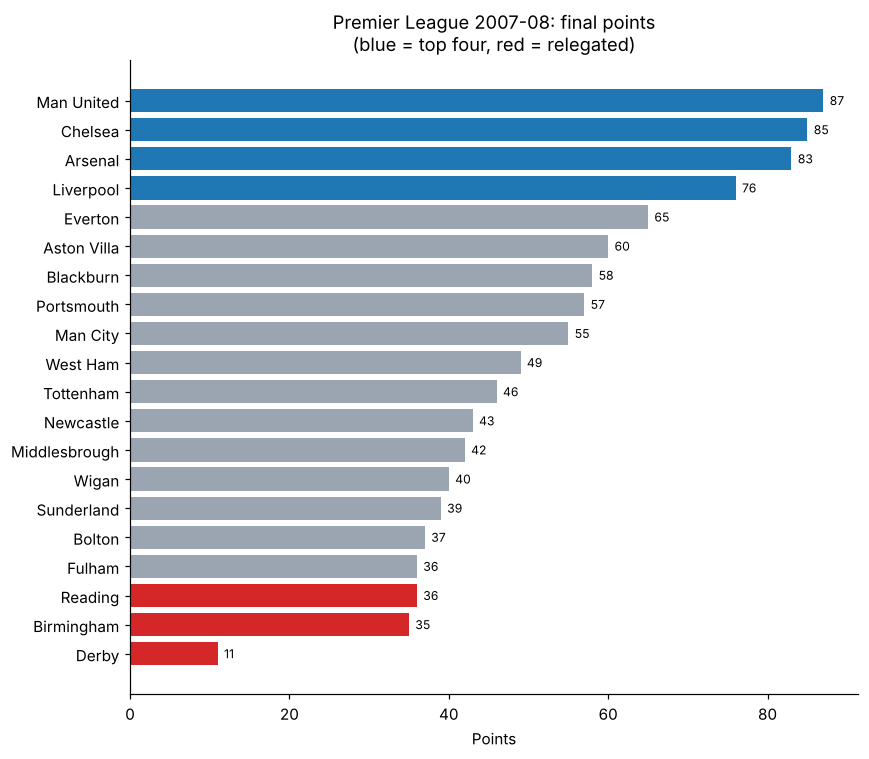

In [5]:
colors = ["#1f77b4" if p <= 4 else "#d62728" if p >= 18 else "#9aa5b1" for p in table["Pos"]]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(table.index[::-1], table["Pts"][::-1], color=colors[::-1])
for y, v in enumerate(table["Pts"][::-1]):
    ax.text(v + 0.8, y, str(v), va="center", fontsize=8)
ax.set_title("Premier League 2007-08: final points\n(blue = top four, red = relegated)")
ax.set_xlabel("Points")
plt.tight_layout(); plt.show()

The title race was tight (87–85–83), but the gap from 4th (Liverpool, 76) to 5th (Everton, 65) was 11 points. The 'Big Four' were a separate tier that season.

## 3. Is home advantage real?
Each match gives a paired observation: home goals vs away goals in the *same* game. A **paired t-test** asks whether the mean difference is zero. Goal counts are not normally distributed, so we confirm the result with the non-parametric **Wilcoxon signed-rank test**.

In [6]:
res_share = df["FTR"].value_counts(normalize=True).reindex(["H", "D", "A"]) * 100
diff = df["FTHG"] - df["FTAG"]

t = stats.ttest_rel(df["FTHG"], df["FTAG"])
w = stats.wilcoxon(df["FTHG"], df["FTAG"])

print(f"Home win {res_share['H']:.1f}% | Draw {res_share['D']:.1f}% | Away win {res_share['A']:.1f}%")
print(f"Mean home goals {df.FTHG.mean():.2f} vs away {df.FTAG.mean():.2f}; mean difference {diff.mean():.2f}")
print(f"Paired t-test: t = {t.statistic:.2f}, p = {t.pvalue:.2g}")
print(f"Wilcoxon:      p = {w.pvalue:.2g}")

Home win 46.3% | Draw 26.3% | Away win 27.4%
Mean home goals 1.53 vs away 1.11; mean difference 0.42
Paired t-test: t = 4.49, p = 9.6e-06
Wilcoxon:      p = 9.3e-06


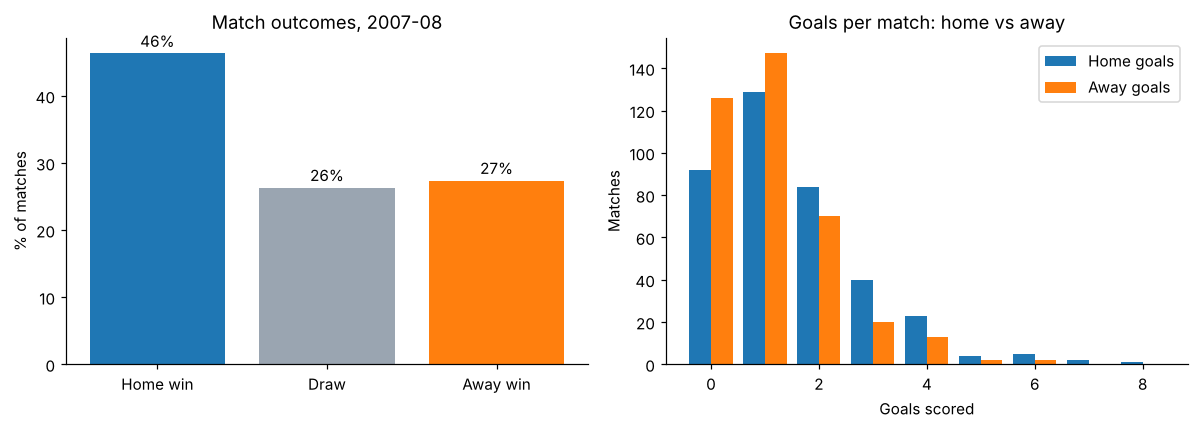

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["Home win", "Draw", "Away win"], res_share.values, color=["#1f77b4", "#9aa5b1", "#ff7f0e"])
for i, v in enumerate(res_share.values):
    axes[0].text(i, v + 1, f"{v:.0f}%", ha="center")
axes[0].set_title("Match outcomes, 2007-08"); axes[0].set_ylabel("% of matches")

bins = np.arange(0, 10) - 0.5
axes[1].hist([df["FTHG"], df["FTAG"]], bins=bins, label=["Home goals", "Away goals"], color=["#1f77b4", "#ff7f0e"])
axes[1].set_title("Goals per match: home vs away"); axes[1].set_xlabel("Goals scored"); axes[1].set_ylabel("Matches")
axes[1].legend()
plt.tight_layout(); plt.show()

**Finding:** home teams scored about 0.42 more goals per game and won about 46% of matches, compared with about 27% for away teams. Both tests reject "no difference" at p < 0.001, so home advantage that season is very unlikely to be noise.

## 4. Volume or quality of shooting?
Two metrics per team:
- **Shot accuracy** = shots on target ÷ shots
- **Conversion rate** = goals ÷ shots on target

In [8]:
table["Shots_pg"]   = table["Shots"] / table["P"]
table["SoT_pg"]     = table["SoT"] / table["P"]
table["Accuracy"]   = table["SoT"] / table["Shots"] * 100
table["Conversion"] = table["GF"] / table["SoT"] * 100
table["SoT_diff_pg"] = (table["SoT"] - table["SoT_against"]) / table["P"]

top4, bottom3 = table[table.Pos <= 4], table[table.Pos >= 18]
summary = pd.DataFrame({
    "Top 4": top4[["Shots_pg", "SoT_pg", "Accuracy", "Conversion"]].mean(),
    "Bottom 3": bottom3[["Shots_pg", "SoT_pg", "Accuracy", "Conversion"]].mean(),
    "League avg": table[["Shots_pg", "SoT_pg", "Accuracy", "Conversion"]].mean(),
}).rename(index={"Shots_pg": "Shots per game", "SoT_pg": "Shots on target per game", "Accuracy": "Shot accuracy %", "Conversion": "Conversion %"})
summary

,Top 4,Bottom 3,League avg
Shots per game,14.83,9.24,11.56
Shots on target per game,8.11,4.93,6.24
Shot accuracy %,54.63,53.41,53.94
Conversion %,23.32,18.93,20.87


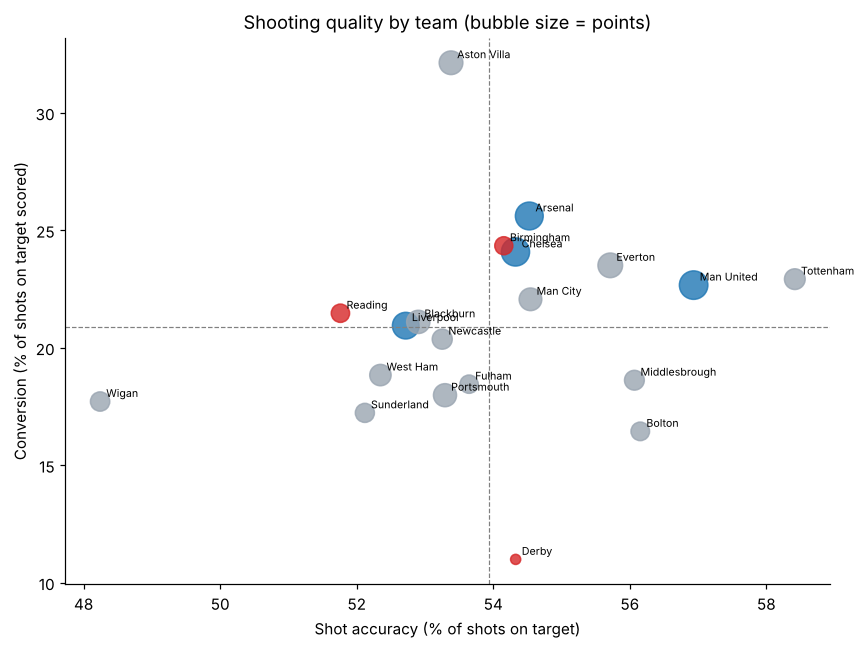

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(table["Accuracy"], table["Conversion"], s=table["Pts"] * 4, color=colors, alpha=0.8)
for team, r in table.iterrows():
    ax.annotate(team, (r.Accuracy, r.Conversion), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.axvline(table.Accuracy.mean(), ls="--", c="grey", lw=0.8); ax.axhline(table.Conversion.mean(), ls="--", c="grey", lw=0.8)
ax.set_xlabel("Shot accuracy (% of shots on target)"); ax.set_ylabel("Conversion (% of shots on target scored)")
ax.set_title("Shooting quality by team (bubble size = points)")
plt.tight_layout(); plt.show()

**Finding (it contradicts a common assumption):** shot *accuracy* was almost identical across tiers, at about 54% for both the top four and the bottom three. The real gap was **volume**: the top four landed about 8.1 shots on target per game against about 4.9 for the relegated sides, about 65% more, because they took more shots in the first place. They also converted somewhat better (about 23% vs 19% of on-target shots scored). Relegated teams' main problem was creating chances, not aiming them.

## 5. Regression: how much does shots-on-target difference explain?
**Model:** `Points = β0 + β1 × (SoT for − SoT against per game) + ε`, estimated by OLS on the 20 teams.

*Caveat:* n = 20 is small, so treat the coefficient as descriptive, not causal. We report heteroskedasticity-robust (HC3) standard errors, which are the safer choice for small samples.

In [10]:
ols = smf.ols("Pts ~ SoT_diff_pg", data=table).fit(cov_type="HC3")
print(ols.summary().tables[1])
print(f"\nR-squared = {ols.rsquared:.2f}")
print(f"Interpretation: +1 shot-on-target difference per game ≈ +{ols.params['SoT_diff_pg']:.1f} points over a season")

                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      52.0000      2.401     21.662      0.000      47.295      56.705
SoT_diff_pg     7.7853      1.464      5.319      0.000       4.917      10.654

R-squared = 0.77
Interpretation: +1 shot-on-target difference per game ≈ +7.8 points over a season


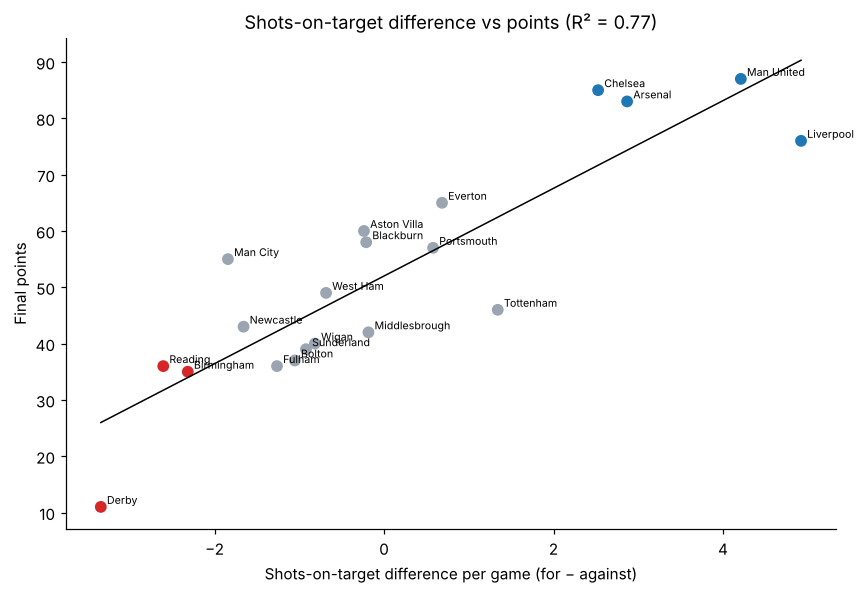

In [11]:
x = np.linspace(table.SoT_diff_pg.min(), table.SoT_diff_pg.max(), 50)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(table["SoT_diff_pg"], table["Pts"], color=colors, s=45)
ax.plot(x, ols.params["Intercept"] + ols.params["SoT_diff_pg"] * x, c="black", lw=1)
for team, r in table.iterrows():
    ax.annotate(team, (r.SoT_diff_pg, r.Pts), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("Shots-on-target difference per game (for − against)"); ax.set_ylabel("Final points")
ax.set_title(f"Shots-on-target difference vs points (R² = {ols.rsquared:.2f})")
plt.tight_layout(); plt.show()

In [12]:
# Residuals: which teams over- or under-performed their shot profile?
table["Expected_Pts"] = ols.fittedvalues.round(1)
table["Over_performance"] = (table["Pts"] - table["Expected_Pts"]).round(1)
table.sort_values("Over_performance", ascending=False)[["Pos", "Pts", "Expected_Pts", "Over_performance"]]

,Pos,Pts,Expected_Pts,Over_performance
Team,,,,
Man City,9,55,37.7,17.3
Chelsea,2,85,71.7,13.3
Aston Villa,6,60,50.2,9.8
Arsenal,3,83,74.3,8.7
Everton,5,65,57.3,7.7
Blackburn,7,58,50.4,7.6
Reading,18,36,31.7,4.3
Newcastle,12,43,39.1,3.9
West Ham,10,49,46.7,2.3


**Finding:** shots-on-target difference alone explains most of the variation in final points (see R² above). The intercept (52) equals the league-average points total, because shots-on-target differences sum to zero across the league. Teams with large positive residuals collected more points than their shot profile predicts, which may reflect finishing, goalkeeping or luck. Teams with negative residuals are candidates for "unlucky", and a scout or analyst would examine them first.

## 6. Conclusions
1. **Home advantage was strong and statistically significant:** about 0.4 extra goals per game, and nearly half of all matches were home wins.
2. **Chance creation separated the top from the bottom, not shot accuracy.** Accuracy was flat (about 54%) across tiers, while on-target shots per game differed by about 65%.
3. **One simple metric, shots-on-target difference, explains most of a season's points table.**

## 7. Limitations and next steps
- One season only. Next, repeat across 2000–2024 (all available on football-data.co.uk) to test stability.
- Shots on target ignore shot *location*, which expected goals (xG) captures. Next step: add xG data (e.g. FBref/Understat).
- Team-level OLS with n = 20 is descriptive. A match-level Poisson model of goals would use all 760 team-match observations.